# 🎓 第1课：一个公式看懂因子投资

**本节目标**：学完你能用一个公式（E[R] = βλ + α）说清楚因子投资的全部世界观。

**怎么用本 notebook（三步法）**：
1. 读 🍚 讲解 cell（白话+比喻）；
2. 运行 🐍 代码 cell（看真实数字）；
3. 完成 ✋ 试一试 cell（改参数，观察变化）。

> 对应原书：第1章 1.1 节

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
def _find_sample():
    for p in [Path('data/sample'), Path.cwd().parents[2] / 'data' / 'sample']:
        if p.exists():
            return p
    raise FileNotFoundError('找不到 data/sample，请从仓库根目录启动 notebook')
SAMPLE = _find_sample()
plt.rcParams['figure.dpi'] = 110
print('✅ 环境就绪，开始学习！')

✅ 环境就绪，开始学习！


## 开场：三个生活问题 🤔

1. 为什么有些股票长期涨得比别的多？（白酒 vs 银行）
2. 为什么大盘一跌，几乎所有股票一起跌？（明明是不同的公司！）
3. 凭什么有人坚信「买便宜股」能赚钱？

**因子投资，就是回答这三个问题的学问。**

## ① 因子 = 食物的「营养成分」 🍚

米饭、肉、菜形态各不相同，但身体真正需要的是背后的**碳水、蛋白质、脂肪**——
这些营养成分就是食物的「因子」。

股票也一样：茅台、宁德、招行公司各不相同，但收益被共同的**系统性风险**驱动
（市场行情、市值大小、便宜还是贵）——这些共同的风险来源，就是股票的**因子**。

**定义（背下来）**：因子 = 众多资产共同暴露的系统性风险，是收益背后的驱动力；
因子收益率 = 这种风险的风险溢价（共性收益）。

**两个必要条件**：
- ✅ 驱动大家一起动（与协方差矩阵有关）；
- ✅ 长期有正收益（被定价）。

> 💡 判断口诀：**它是很多股票收益的共同原因吗？长期持有它能赚钱吗？** 两个都「是」才是因子。

## ② 案例1：什么是「因子暴露 β」？📏

β = 你对这种风险的**敞口**。先看代码：模拟市场收益，造两支股票——
股票A 对市场很敏感（β=1.2），股票B 不敏感（β=0.3）。

股票A 的 β 估计 = 1.16（预设1.2）
股票B 的 β 估计 = 0.24（预设0.3）


C:\Users\Admin\AppData\Local\Temp\ipykernel_9180\1608663410.py:18: UserWarning: Glyph 24066 (\N{CJK UNIFIED IDEOGRAPH-5E02}) missing from font(s) DejaVu Sans.
  plt.legend(); plt.tight_layout(); plt.show()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9180\1608663410.py:18: UserWarning: Glyph 22330 (\N{CJK UNIFIED IDEOGRAPH-573A}) missing from font(s) DejaVu Sans.
  plt.legend(); plt.tight_layout(); plt.show()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9180\1608663410.py:18: UserWarning: Glyph 25910 (\N{CJK UNIFIED IDEOGRAPH-6536}) missing from font(s) DejaVu Sans.
  plt.legend(); plt.tight_layout(); plt.show()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9180\1608663410.py:18: UserWarning: Glyph 30410 (\N{CJK UNIFIED IDEOGRAPH-76CA}) missing from font(s) DejaVu Sans.
  plt.legend(); plt.tight_layout(); plt.show()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9180\1608663410.py:18: UserWarning: Glyph 20010 (\N{CJK UNIFIED IDEOGRAPH-4E2A}) missing from font(s) DejaVu Sans.
  plt.legend(); p

C:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20010 (\N{CJK UNIFIED IDEOGRAPH-4E2A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 32929 (\N{CJK UNIFIED IDEOGRAPH-80A1}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 25910 (\N{CJK UNIFIED IDEOGRAPH-6536}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 30410 (\N{CJK UNIFIED IDEOGRAPH-76CA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Admin\AppData\Local\Programs\Python

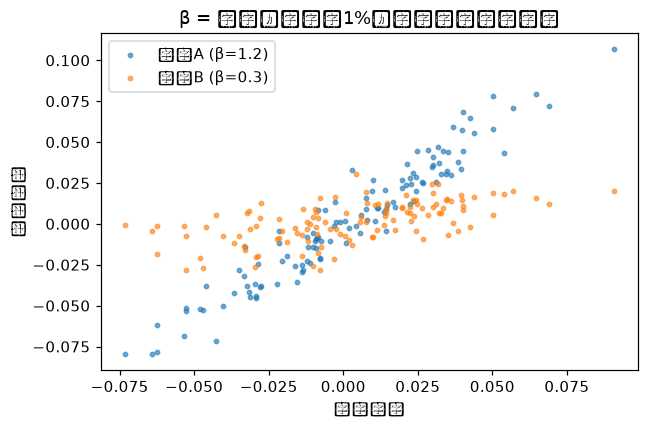

In [2]:
rng = np.random.default_rng(42)
T = 120
market = rng.normal(0.005, 0.04, T)          # 市场因子收益
stockA = 1.2 * market + rng.normal(0, 0.01, T)  # β=1.2
stockB = 0.3 * market + rng.normal(0, 0.01, T)  # β=0.3

# 用回归估计 β（斜率）
betaA = np.polyfit(market, stockA, 1)[0]
betaB = np.polyfit(market, stockB, 1)[0]
print(f'股票A 的 β 估计 = {betaA:.2f}（预设1.2）')
print(f'股票B 的 β 估计 = {betaB:.2f}（预设0.3）')

plt.figure(figsize=(6, 4))
plt.scatter(market, stockA, s=8, alpha=0.6, label='股票A (β=1.2)')
plt.scatter(market, stockB, s=8, alpha=0.6, label='股票B (β=0.3)')
plt.xlabel('市场收益'); plt.ylabel('个股收益')
plt.title('β = 斜率：市场涨1%，个股平均跟涨多少')
plt.legend(); plt.tight_layout(); plt.show()

## ③ 一个公式：E[R] = βλ + α 🧮

收益不是猜的，是算出来的：

$$E[R_i] = \beta_i \lambda + \alpha_i$$

| 成分 | 白话 | 例子 |
|---|---|---|
| β 因子暴露 | 你对这种风险敞开多少 | 茅台 β=1.2，银行 β=0.6 |
| λ 因子溢价 | 这种风险值多少钱（月均） | 市场 λ=0.5%/月，便宜因子 λ=0.8%/月 |
| α 定价误差 | 模型算不出的额外收益 | 有的股票 α=0.3%/月 |

λ 是**因子**（市场付钱的原因），βλ 是**多因子模型**（配餐表），α 是**异象**（付错的钱）。

In [3]:
# 案例2：用教学小样本算预期收益（4 支股票 × 2 个因子）
teach = pd.read_csv(SAMPLE / 'teaching_sample.csv')
lam = np.array([0.008, 0.004])  # 因子溢价：A=0.8%/月, B=0.4%/月
beta = teach[['factor_a_exposure', 'factor_b_exposure']].to_numpy()
er_model = beta @ lam  # 矩阵乘法：暴露 × 溢价
pd.DataFrame({'资产': teach['asset'], 'β_A': beta[:, 0], 'β_B': beta[:, 1],
             'E[R]模型(月)': er_model}).round(4)

,资产,β_A,β_B,E[R]模型(月)
0,stock_1,1.2,0.8,0.0128
1,stock_2,1.1,1.3,0.0140
2,stock_3,0.9,-0.8,0.0040
3,stock_4,0.8,-1.3,0.0012


## ④ 案例3：人造一个「异象」 ⭐

给 stock_2 注入 1.2%/月的真实 α——它就成了模型解释不了的「异象」。
画出来看：**点到模型直线的垂直距离 = α**。

C:\Users\Admin\AppData\Local\Temp\ipykernel_9180\1630984974.py:17: UserWarning: Glyph 22240 (\N{CJK UNIFIED IDEOGRAPH-56E0}) missing from font(s) DejaVu Sans.
  ax.legend(fontsize=8); plt.tight_layout(); plt.show()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9180\1630984974.py:17: UserWarning: Glyph 23376 (\N{CJK UNIFIED IDEOGRAPH-5B50}) missing from font(s) DejaVu Sans.
  ax.legend(fontsize=8); plt.tight_layout(); plt.show()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9180\1630984974.py:17: UserWarning: Glyph 26292 (\N{CJK UNIFIED IDEOGRAPH-66B4}) missing from font(s) DejaVu Sans.
  ax.legend(fontsize=8); plt.tight_layout(); plt.show()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9180\1630984974.py:17: UserWarning: Glyph 38706 (\N{CJK UNIFIED IDEOGRAPH-9732}) missing from font(s) DejaVu Sans.
  ax.legend(fontsize=8); plt.tight_layout(); plt.show()
C:\Users\Admin\AppData\Local\Temp\ipykernel_9180\1630984974.py:17: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from fo

C:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 39044 (\N{CJK UNIFIED IDEOGRAPH-9884}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 26399 (\N{CJK UNIFIED IDEOGRAPH-671F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 25910 (\N{CJK UNIFIED IDEOGRAPH-6536}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Admin\AppData\Local\Programs\Python\Python314\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 30410 (\N{CJK UNIFIED IDEOGRAPH-76CA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\Admin\AppData\Local\Programs\Python

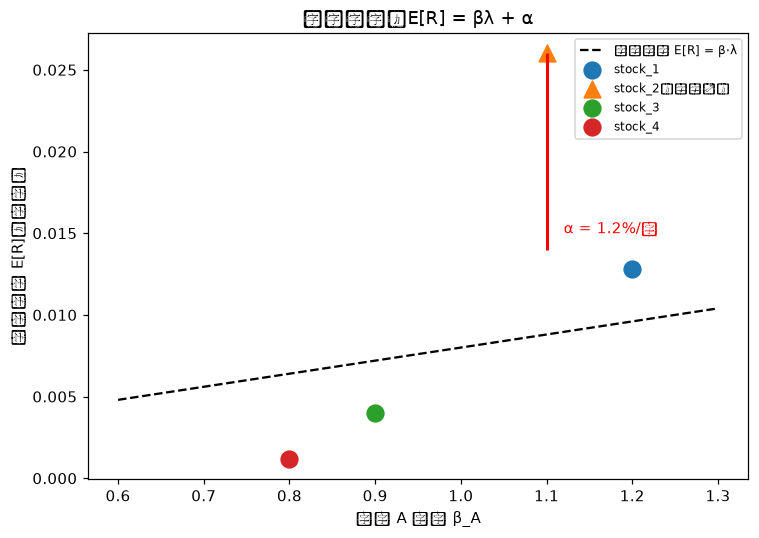

In [4]:
alpha = np.array([0.0, 0.012, 0.0, 0.0])   # 只有 stock_2 有 α
er_actual = er_model + alpha
fig, ax = plt.subplots(figsize=(7, 5))
xs = np.linspace(0.6, 1.3, 10)
ax.plot(xs, xs * lam[0], 'k--', label='模型直线 E[R] = β·λ')
for i, row in teach.iterrows():
    b = beta[i, 0]
    is_anom = alpha[i] != 0
    ax.scatter(b, er_actual[i], s=120, marker='^' if is_anom else 'o',
               label=f"{row['asset']}" + ('（异象⭐）' if is_anom else ''))
    if is_anom:
        ax.vlines(b, er_model[i], er_actual[i], color='red', linewidth=2)
        ax.annotate('α = 1.2%/月', xy=(b, er_model[i]),
                    xytext=(b + 0.02, er_model[i] + 0.001), color='red')
ax.set_xlabel('因子 A 暴露 β_A'); ax.set_ylabel('预期收益 E[R]（月均）')
ax.set_title('统一视角：E[R] = βλ + α')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## ⑤ 截面 vs 时序 + 降维魔法 🧙

- **截面** 🏙️：为什么北京比鹤岗贵？（不同资产的收益差异）
- **时序** 📅：北京今年比去年涨了多少？（同一资产随时间的变化）

时序角度的核心产出——**方差模型**（式1.6）：

$$\Sigma = \beta \Sigma_\lambda \beta' + \Sigma_\varepsilon$$

**这就是降维魔法**：3000 支股票的协方差是 3000×3000 的矩阵（450万个数字！），
用 10 个因子就缩成 10×10。下面亲手验证。

In [5]:
# 案例4：模拟 120 个月，验证协方差分解 Σ = βΣλβ' + Σε
rng = np.random.default_rng(42)
T = 120
cov_lam = np.array([[0.0009, 0.0001], [0.0001, 0.0004]])  # 因子协方差
lam_t = rng.multivariate_normal(lam, cov_lam, size=T)     # 因子收益时序
idio = rng.normal(0, teach['idio_risk'].to_numpy(), size=(T, 4)).T
ret = alpha.reshape(-1, 1) + beta @ lam_t.T + idio        # 个股收益（式1.5）

# 用因子重建协方差 vs 直接算样本协方差
sigma_eps = np.diag(teach['idio_risk'].to_numpy() ** 2)
sigma_hat = beta @ cov_lam @ beta.T + sigma_eps
sigma_true = np.cov(ret)
err = np.abs(sigma_hat - sigma_true).max()
print(f'重建协方差 vs 真实协方差的最大误差: {err:.5f}')
print('=> Σ = βΣλβ′ + Σε 成立，这就是「因子=降维」的数学依据')

重建协方差 vs 真实协方差的最大误差: 0.00043
=> Σ = βΣλβ′ + Σε 成立，这就是「因子=降维」的数学依据


## ✋ 试一试（动手任务）

1. 把上面 `alpha` 数组全部改成 0 重跑案例3——红色竖线发生了什么？为什么？
2. 在案例2里给 teach 加一行「新股票」（β=[1.0, 0.6]），算它的 E[R]。
3. 把 `cov_lam` 的非对角元改成 0.0005 重跑案例4——误差变大还是变小？为什么？

## ✅ 本节小结

- 预期收益 = 暴露 × 溢价 + 定价误差（**E[R] = βλ + α**）；
- **α ≠ 0** 的资产 = 异象（模型解释不了的部分）；
- 协方差分解 Σ = βΣλβ′ + Σε 是**降维**的数学依据（Barra 的应用基础）。

> 下一课：学术起源——三位诺奖大师和「因子动物园」。